# Infinite-ISP 交互式可视化

逐个模块检查 ISP 到底做了什么。

## Step 1 — 把 IMX219 的原始数据读出来并显示

这一步只做一件事：**把 sensor 吐出来的那一坨字节，变成一张能看的图**。

中间要跨过三道坎：

1. **解包（unpack）** — 文件里每个像素只占 10 bit（1.25 字节），不是 numpy 能直接读的 16 bit
2. **理解它是 CFA 图** — 解包出来是单通道的 Bayer 马赛克，不是 RGB
3. **显示** — 原始数据是线性的，直接显示会一片漆黑，要加 gamma

### 1.1 准备路径和参数

In [2]:
import sys
from pathlib import Path

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 让 matplotlib 的标题能显示中文（挑一个系统里装了的字体）
_installed = {f.name for f in fm.fontManager.ttflist}
for _f in ["PingFang SC", "Hiragino Sans GB", "Heiti TC", "Arial Unicode MS",
           "Noto Sans CJK SC", "Microsoft YaHei", "SimHei"]:
    if _f in _installed:
        matplotlib.rcParams["font.sans-serif"] = [_f]
        matplotlib.rcParams["axes.unicode_minus"] = False
        break

# notebook 在 CLI_interface/ 里，往上一级才是仓库根目录
ISP_ROOT = Path.cwd().parent if Path.cwd().name == "CLI_interface" else Path.cwd()
sys.path.insert(0, str(ISP_ROOT))          # 后面几步要 import infinite_isp / modules

RAW_PATH = ISP_ROOT / "in_frames/imx_219/handle_34661_chn0_1920x1080_stride_2400_frameid_56_ts_602564431716450.raw"

# 这些参数全部来自文件名和 sensor 的配置文件 linear_1920x1080_raw10_30fps_1lane.c
WIDTH, HEIGHT = 1920, 1080
BIT_DEPTH     = 10
STRIDE        = 2400          # 每行实际占用的字节数
BAYER         = "rggb"
BLACK_LEVEL   = 64            # IMX219 10-bit 的黑电平基座
WHITE_LEVEL   = 2 ** BIT_DEPTH - 1

print("raw 文件:", RAW_PATH.name)
print("存在:", RAW_PATH.exists(), "| 大小:", RAW_PATH.stat().st_size, "字节")

raw 文件: handle_34661_chn0_1920x1080_stride_2400_frameid_56_ts_602564431716450.raw
存在: True | 大小: 2592000 字节


### 1.2 先搞清楚文件里到底是什么

`2592000` 字节 / `1080` 行 = 每行 `2400` 字节，和文件名里的 `stride_2400` 对上了。

而一行有 1920 个像素，`2400 / 1920 = 1.25` 字节/像素 —— **正好是 10 bit**。

所以这不是 numpy 一句 `fromfile(dtype=uint16)` 能读的东西：那样读每个像素要占 2 字节，文件得有 4147200 字节才够。
数据是**打包（packed）**的，5 个字节里塞了 4 个像素。

In [3]:
n_bytes = RAW_PATH.stat().st_size
print(f"总字节数        : {n_bytes}")
print(f"每行字节数      : {n_bytes // HEIGHT}   (文件名里的 stride)")
print(f"每像素字节数    : {n_bytes / HEIGHT / WIDTH}   -> 10 bit packed")
print(f"若按 uint16 读需: {WIDTH * HEIGHT * 2} 字节   (差 {WIDTH*HEIGHT*2 - n_bytes} 字节)")

# 看一眼最原始的字节长什么样 —— 此刻它还只是一串数字，毫无意义
raw_bytes = np.fromfile(RAW_PATH, dtype=np.uint8)
print("\n前 20 个字节:", raw_bytes[:20])

总字节数        : 2592000
每行字节数      : 2400   (文件名里的 stride)
每像素字节数    : 1.25   -> 10 bit packed
若按 uint16 读需: 4147200 字节   (差 1555200 字节)

前 20 个字节: [ 66  41 185  20 135  88  81  89  22 151 111 229  72  19 154  94 189  89
  21 140]


### 1.3 解包前长什么样

既然文件里就是一串字节，那干脆**直接把它当成一张 2400×1080 的 8-bit 灰度图**显示出来。

结果很有意思：场景是认得出来的，但有两个明显的毛病 ——

1. **横向被拉长了 1.25 倍**（2400 列而不是 1920 列），因为每个像素占了 1.25 个字节
2. **整张图盖着一层"噪声"**，那不是真的噪声，是跨在像素边界上的字节

把每 5 个字节拆成 5 个平面单独看，第 2 条就清楚了。

In [4]:
raw_rows = np.fromfile(RAW_PATH, dtype=np.uint8)[:STRIDE * HEIGHT].reshape(HEIGHT, STRIDE)
planes = raw_rows[:, :WIDTH * 5 // 4].reshape(HEIGHT, -1, 5)   # 每行切成 N 组，每组 5 字节

fig, ax = plt.subplots(figsize=(13, 6))
ax.imshow(raw_rows, cmap="gray", vmin=0, vmax=255, aspect="auto")
ax.set_title(f"解包前：{STRIDE} x {HEIGHT} 的字节流直接当 8-bit 灰度图")
ax.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 5, figsize=(18, 4.2))
for j in range(5):
    pl = planes[:, :, j]
    hdiff = np.abs(np.diff(pl.astype(np.float32), axis=1)).mean()   # 左右相邻的平均跳变
    ax[j].imshow(pl, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax[j].set_title(f"字节 b{j}\nmean={pl.mean():.0f}  相邻跳变={hdiff:.1f}", fontsize=10)
    ax[j].axis("off")
plt.suptitle("每组 5 个字节拆开看：b0 / b4 是干净的图，b1 / b2 / b3 是噪声", y=1.04)
plt.tight_layout()
plt.show()

/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 35299 (\N{CJK UNIFIED IDEOGRAPH-89E3}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 21253 (\N{CJK UNIFIED IDEOGRAPH-5305}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 23383 (\N{CJK UNIFIED IDEOGRAPH-5B57}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:8: UserWarning: Glyph 33410 (\N{CJK UNIFIED IDEOGRAPH-8282}) missing from current font.
  plt.tight_layout()
/tm

<Figure size 1300x600 with 1 Axes>

/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 23383 (\N{CJK UNIFIED IDEOGRAPH-5B57}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 33410 (\N{CJK UNIFIED IDEOGRAPH-8282}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 37051 (\N{CJK UNIFIED IDEOGRAPH-90BB}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 36339 (\N{CJK UNIFIED IDEOGRAPH-8DF3}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 21464 (\N{CJK UNIFIED IDEOGRAPH-53D8}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/954217833.py:19: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from current font.
  plt.

<Figure size 1800x420 with 5 Axes>

为什么 b0 和 b4 干净，中间三个是噪声？因为**只有它们没跨在像素边界上**：

- `b0` 装的是 p0 的**低 8 位**。这张图偏暗（均值 166），绝大多数像素值 < 256，所以 `b0` 基本就等于 p0 本身 → 干净
- `b4` 装的是 p3 的**高 8 位**，相当于 `p3 >> 2` → 干净，但亮度只有 1/4（均值 41，正好是 166/4）
- `b1` `b2` `b3` 每个都横跨两个像素，高位来自这个像素、低位来自下一个 → 两个不相关的数拼在一起，自然是噪声

这也是**整张图那层"噪声"的来源**：5 列里有 3 列是垃圾。

### 1.3.1 手算一组，看清楚位是怎么排的

In [5]:
ROW, BYTE0 = 580, 1275          # BYTE0 取 5 的倍数，才对齐到组边界
grp = raw_rows[ROW, BYTE0:BYTE0 + 5]

print(f"第 {ROW} 行、第 {BYTE0}~{BYTE0 + 4} 个字节:")
print("        b0        b1        b2        b3        b4")
print("十进制  " + "  ".join(f"{v:8d}" for v in grp))
print("二进制  " + "  ".join(f"{v:08b}" for v in grp))

# 小端位流：每个字节内部也是低位在前，所以每个字节的二进制要先翻转再拼接
stream = "".join(f"{v:08b}"[::-1] for v in grp)
print("\n拼成一条低位在前的 bit 流，每 10 bit 切一刀:")
for i in range(4):
    bits = stream[i * 10:(i + 1) * 10]
    print(f"  p{i} = {bits}  ->  {int(bits[::-1], 2):4d}")

print(f"\n这 4 个值对应图像上的 raw[{ROW}, {BYTE0 // 5 * 4}:{BYTE0 // 5 * 4 + 4}]，下一节解包完可以回来核对。")

第 580 行、第 1275~1279 个字节:
        b0        b1        b2        b3        b4
十进制       112       160        65       136        26
二进制  01110000  10100000  01000001  10001000  00011010

拼成一条低位在前的 bit 流，每 10 bit 切一刀:
  p0 = 0000111000  ->   112
  p1 = 0001011000  ->   104
  p2 = 0010000100  ->   132
  p3 = 0101011000  ->   106

这 4 个值对应图像上的 raw[580, 1020:1024]，下一节解包完可以回来核对。


### 1.4 解包：5 字节 → 4 像素

IMX219 经过这块板子的 VIN 之后，用的是**小端连续位流**：把一行的像素值首尾相接写成一条 bit 流，
每 10 bit 一个像素，低位在前。于是每 5 个字节 `b0 b1 b2 b3 b4` 刚好装下 4 个像素：

```
         b0        b1        b2        b3        b4
      [76543210][76543210][76543210][76543210][76543210]
 p0 =  ********  **                                        b0 | (b1 & 0x03) << 8
 p1 =            ******  ****                             (b1 >> 2) | (b2 & 0x0F) << 6
 p2 =                    ****  ******                     (b2 >> 4) | (b3 & 0x3F) << 4
 p3 =                            **  ********             (b3 >> 6) |  b4         << 2
```

> ⚠️ 这里有个坑：标准的 MIPI CSI-2 RAW10 是另一种排法（前 4 个字节各放一个像素的高 8 位，
> 第 5 个字节放 4 个像素的低 2 位）。如果用那种排法解这份数据，解出来是满屏噪点。

In [6]:
def unpack_raw10(path, width, height, stride):
    """packed 10-bit 小端位流 -> (height, width) 的 uint16 数组"""
    data = np.fromfile(path, dtype=np.uint8)
    row_bytes = width * 5 // 4                       # 一行有效数据的字节数
    rows = data[:stride * height].reshape(height, stride)[:, :row_bytes]
    g = rows.reshape(height, -1, 5).astype(np.uint16)   # 每行切成 N 个 5 字节的组

    out = np.empty((height, width), np.uint16)
    out[:, 0::4] =  g[:, :, 0]       | ((g[:, :, 1] & 0x03) << 8)
    out[:, 1::4] = (g[:, :, 1] >> 2) | ((g[:, :, 2] & 0x0F) << 6)
    out[:, 2::4] = (g[:, :, 2] >> 4) | ((g[:, :, 3] & 0x3F) << 4)
    out[:, 3::4] = (g[:, :, 3] >> 6) |  (g[:, :, 4]         << 2)
    return out


raw = unpack_raw10(RAW_PATH, WIDTH, HEIGHT, STRIDE)

print("shape:", raw.shape, "| dtype:", raw.dtype)
print(f"取值范围: {raw.min()} ~ {raw.max()}  (10-bit 理论范围 0 ~ {WHITE_LEVEL})")
print(f"均值: {raw.mean():.1f}")
print(f"最暗的 0.05%: {np.percentile(raw, 0.05):.0f}  <- 这就是黑电平，应该等于 {BLACK_LEVEL}")
print(f"过曝像素占比: {(raw >= WHITE_LEVEL).mean() * 100:.2f}%")
print(f"\n回头核对 1.3.1 手算的那一组: raw[580, 1020:1024] = {raw[580, 1020:1024]}")

shape: (1080, 1920) | dtype: uint16
取值范围: 34 ~ 1023  (10-bit 理论范围 0 ~ 1023)
均值: 174.1
最暗的 0.05%: 65  <- 这就是黑电平，应该等于 64
过曝像素占比: 0.00%

回头核对 1.3.1 手算的那一组: raw[580, 1020:1024] = [112 104 132 106]


解包是否正确，有两个硬指标可以自检：

- **黑电平 = 64**。IMX219 10-bit 输出的黑电平基座固定是 64，这个数字对上了说明高低位没错位。
- **最大值 = 1023**。如果位宽解错了，最大值会卡在 255 或者溢出到更大。

### 1.5 显示：为什么要加 gamma

现在 `raw` 是一张 1920×1080 的单通道图。直接 `imshow` 会很黑 —— 因为 sensor 输出是**线性**的，
而人眼对亮度的感知接近 `亮度^(1/2.2)`。显示前套一个 gamma 才能看到暗部细节。

下面左边是不加 gamma 的原始线性数据，右边是加了 gamma 的。

/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2232246973.py:11: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from current font.

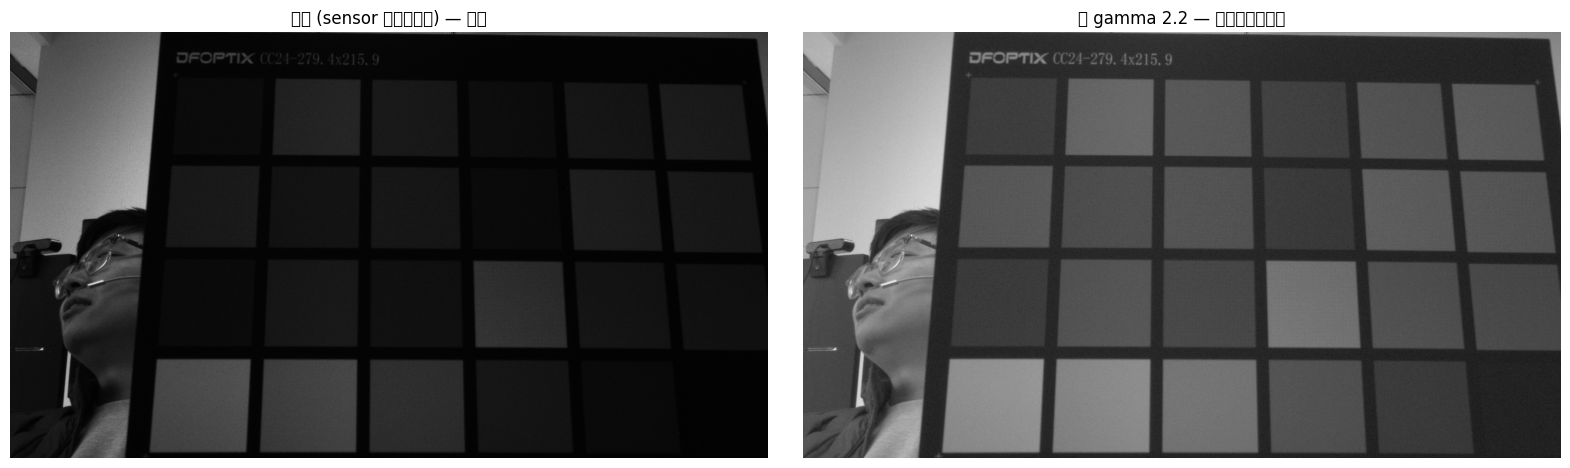

In [7]:
# 归一化到 0~1；先减黑电平，这样真正的"黑"才是 0
norm = np.clip((raw.astype(np.float32) - BLACK_LEVEL) / (WHITE_LEVEL - BLACK_LEVEL), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
ax[0].imshow(norm, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("线性 (sensor 的原始输出) — 偏暗")
ax[1].imshow(norm ** (1 / 2.2), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("加 gamma 2.2 — 接近人眼看到的")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

### 1.6 它其实不是灰度图，是 Bayer 马赛克

上面看着像灰度图，但每个像素其实只记录了**一种颜色**。sensor 上盖着一层滤色片阵列（CFA），
IMX219 是 `rggb` 排列，每 2×2 一个单元：

```
(0,0)=R  (0,1)=Gr
(1,0)=Gb (1,1)=B
```

放大到像素级就能看出这个 2×2 的周期性明暗格子 —— 那不是噪声，是 R/G/B 三种滤色片透光率不同造成的。

/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 32032 (\N{CJK UNIFIED IDEOGRAPH-7D20}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 25918 (\N{CJK UNIFIED IDEOGRAPH-653E}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 30475 (\N{CJK UNIFIED IDEOGRAPH-770B}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 24471 (\N{CJK UNIFIED IDEOGRAPH-5F97}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/2132350830.py:20: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}) missing from current font.

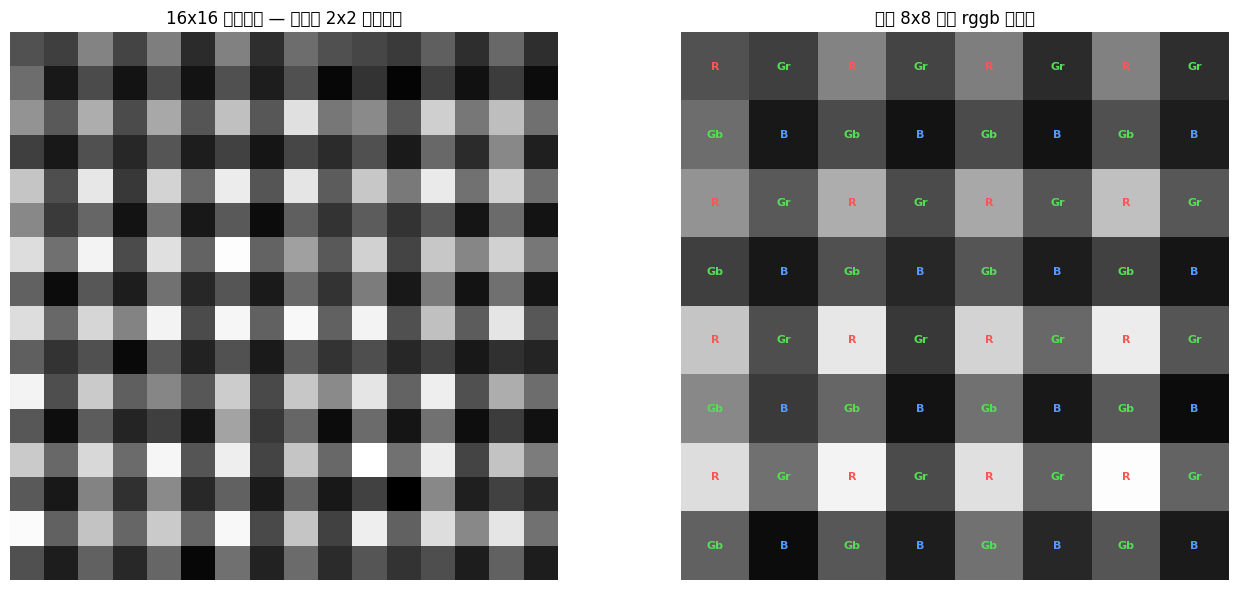

In [8]:
y0, x0, N = 580, 1020, 16          # 天花板上一块明亮且平坦的区域
patch = raw[y0:y0+N, x0:x0+N]

fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.25]})

ax[0].imshow(patch, cmap="gray", interpolation="nearest")
ax[0].set_title(f"{N}x{N} 像素放大 — 看得到 2x2 的棋盘格")
ax[0].axis("off")

ax[1].imshow(patch, cmap="gray", interpolation="nearest")
labels = [["R", "Gr"], ["Gb", "B"]]
colors = [["#ff5555", "#55dd55"], ["#55dd55", "#5599ff"]]
for i in range(8):
    for j in range(8):
        ax[1].text(j, i, labels[i % 2][j % 2], color=colors[i % 2][j % 2],
                   ha="center", va="center", fontsize=8, fontweight="bold")
ax[1].set_xlim(-0.5, 7.5); ax[1].set_ylim(7.5, -0.5)
ax[1].set_title("左上 8x8 标出 rggb 的相位")
ax[1].axis("off")
plt.tight_layout()
plt.show()

### 1.7 拆成四个通道，顺便验证 Bayer 相位

把 2×2 的四个位置各自抽出来，就得到四张 960×540 的图。

验证相位对不对有个很好用的办法：**Gr 和 Gb 是同一种颜色**，所以这两张图应该几乎一模一样
（比值 ≈ 1.000，相关系数 > 0.99）。而 R 和 B 跟它们都会有明显差别。

哪条对角线是绿色，就决定了是 `rggb`/`bggr`（绿在副对角线）还是 `grbg`/`gbrg`（绿在主对角线）。

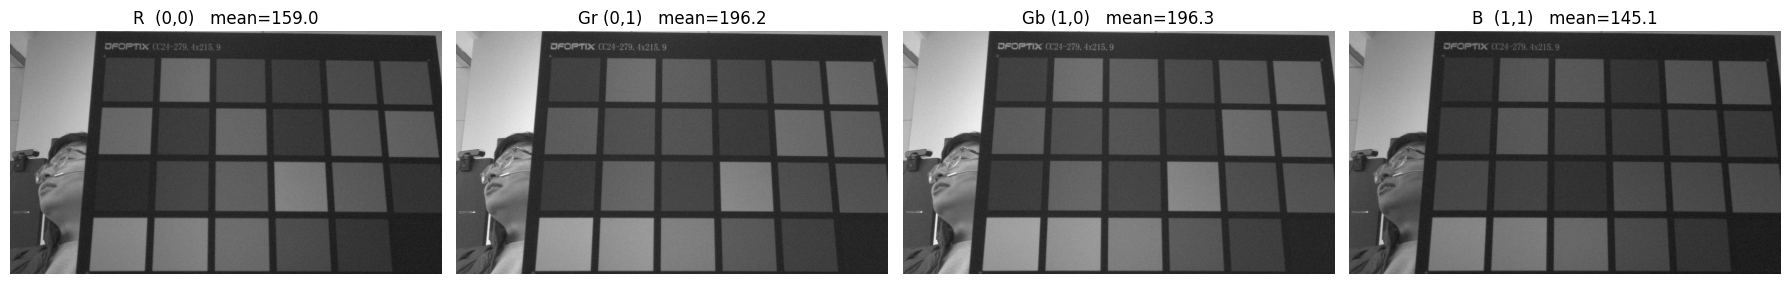

两条对角线的比值稳定性（真正的绿色对 -> 比值≈1、CV 很小、相关系数≈1）:
  R  (0,0) / B  (1,1) :  ratio=1.160  CV=0.2827  corr=0.9148
  Gr (0,1) / Gb (1,0) :  ratio=1.001  CV=0.0297  corr=0.9989


In [9]:
ch = {
    "R  (0,0)": raw[0::2, 0::2],
    "Gr (0,1)": raw[0::2, 1::2],
    "Gb (1,0)": raw[1::2, 0::2],
    "B  (1,1)": raw[1::2, 1::2],
}

fig, ax = plt.subplots(1, 4, figsize=(18, 3.2))
for a, (name, plane) in zip(ax, ch.items()):
    p = np.clip((plane.astype(np.float32) - BLACK_LEVEL) / (WHITE_LEVEL - BLACK_LEVEL), 0, 1)
    a.imshow(p ** (1 / 2.2), cmap="gray", vmin=0, vmax=1)
    a.set_title(f"{name}   mean={plane.mean():.1f}")
    a.axis("off")
plt.tight_layout()
plt.show()

# 相位自检：对两条对角线分别算比值的稳定性
def blockmean(a, n=8):
    h, w = a.shape[0] // n * n, a.shape[1] // n * n
    return a[:h, :w].reshape(h // n, n, w // n, n).mean((1, 3))   # 8x8 平均，压掉噪声

b = {k: blockmean(v.astype(np.float32)) for k, v in ch.items()}
mask = np.ones_like(b["R  (0,0)"], bool)
for v in b.values():
    mask &= (v > 100) & (v < 1000)        # 只看既不欠曝也不过曝的区域

print("两条对角线的比值稳定性（真正的绿色对 -> 比值≈1、CV 很小、相关系数≈1）:")
for a_, c_ in [("R  (0,0)", "B  (1,1)"), ("Gr (0,1)", "Gb (1,0)")]:
    r = b[a_][mask] / b[c_][mask]
    corr = np.corrcoef(b[a_][mask], b[c_][mask])[0, 1]
    print(f"  {a_} / {c_} :  ratio={r.mean():.3f}  CV={r.std()/r.mean():.4f}  corr={corr:.4f}")

### 1.8 最粗糙的"彩色"预览

还没到 demosaic 模块，但可以用最笨的办法先看一眼颜色：**2×2 直接降采样**，
R 取 (0,0)、G 取两个绿的平均、B 取 (1,1)，得到一张 960×540 的 RGB 图。

再顺手做一次灰世界白平衡（因为 sensor 的绿色通道最灵敏，不补增益的话整张图是绿的）。

这张图**不是** ISP 的输出，只是用来确认数据读对了。真正的 demosaic / WB / CCM 是后面几步的事。

参与统计的像素  74.4%
灰世界估出的增益  R=1.397  G=1.000  B=1.636


/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 26080 (\N{CJK UNIFIED IDEOGRAPH-65E0}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 30333 (\N{CJK UNIFIED IDEOGRAPH-767D}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 34913 (\N{CJK UNIFIED IDEOGRAPH-8861}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 25972 (\N{CJK UNIFIED IDEOGRAPH-6574}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_565066/20601936.py:24: UserWarning: Glyph 20559 (\N{CJK UNIFIED IDEOGRAPH-504F}) missing from current font.
  plt.tight_l

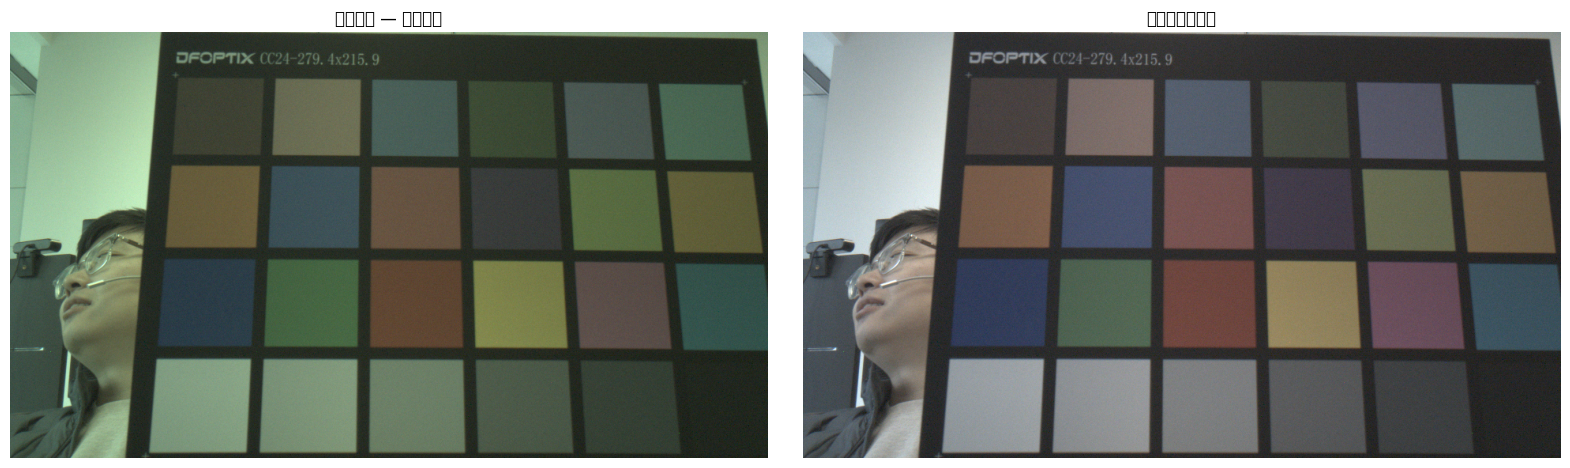

In [10]:
f = raw.astype(np.float32) - BLACK_LEVEL
R = np.clip(f[0::2, 0::2], 0, None)
G = np.clip((f[0::2, 1::2] + f[1::2, 0::2]) / 2, 0, None)
B = np.clip(f[1::2, 1::2], 0, None)

rgb_raw = np.stack([R, G, B], axis=-1) / (WHITE_LEVEL - BLACK_LEVEL)

# 灰世界白平衡：把 R、B 的均值拉到和 G 一样。
# 坑：统计前必须把过曝和近黑的像素剔掉。这帧有 6.7% 的像素被灯 panel 顶到 1023，
# 三个通道一起被削平成等值，混进来算会把增益硬生生拉回 1，白平衡就等于没做。
valid = (G > 30) & (G < 850) & (R < 850) & (B < 850)
gain = np.array([G[valid].mean() / R[valid].mean(), 1.0, G[valid].mean() / B[valid].mean()])
print(f"参与统计的像素  {valid.mean() * 100:.1f}%")
print(f"灰世界估出的增益  R={gain[0]:.3f}  G=1.000  B={gain[2]:.3f}")
rgb_wb = rgb_raw * gain

fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
ax[0].imshow(np.clip(rgb_raw, 0, 1) ** (1 / 2.2))
ax[0].set_title("无白平衡 — 整体偏绿")
ax[1].imshow(np.clip(rgb_wb, 0, 1) ** (1 / 2.2))
ax[1].set_title("灰世界白平衡后")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

---

## 这一步做了什么（小结）

| 阶段 | 输入 | 输出 | 关键点 |
|---|---|---|---|
| 读文件 | 2592000 个 `uint8` | 一维字节流 | stride=2400，每像素 1.25 字节 |
| 解包 | 字节流 | `(1080, 1920)` `uint16` | 小端 10-bit 位流，5 字节→4 像素 |
| 自检 | `uint16` 数组 | 黑电平 64 / 最大 1023 | 对上了说明没有错位 |
| 显示 | 线性数据 | 加 gamma 的图 | 线性数据直接显示会偏暗 |
| 拆通道 | Bayer 马赛克 | 4 张 960×540 | Gr≈Gb 可以反过来验证 `rggb` |

**此刻 `raw` 这个变量里躺着的，就是 ISP pipeline 的输入。** 它还没有经过任何处理：
黑电平没减、没去坏点、没白平衡、没去马赛克、没有颜色校正。

下一步（Step 2）就可以开始一个模块一个模块地往下走，每一步都把前后对比画出来。